# Credit Card Fraud Detection — Exploratory Data Analysis

**Objective:** Understand the structure, quality and statistical properities of the transaction data before building a classifier — identify class imbalance severity, feature signal strength, and preprocessing requirements that will shape the modeling strategy.

**Dataset** Anonymized credit card transactions(`Time`, `Amount`, PCA-transformed featuures `V1` — `V28`, and the binary target `Class`, where `1` = Fraudulent transaction and `0` = Normal transaction)

**Contents**
1. [Data Overview & Quality Check](#1)
2. [Class Imbalance](#2)
3. [Time & Amount Analysis](#3)
4. [Correlation Analysis](#4)
5. [Statistical Feature Significance](#5)
6. [Outlier Analysis (IQR method)](#6)
7. [Distribution Comparison for Top Features](#7)
8. [Key Findings in EDA](#8)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp, mannwhitneyu
import warnings
warnings.filterwarnings('ignore')

In [2]:
DATA_PATH = 'data/train.csv'
df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape[0]: ,} rows x {df.shape[1]} columns')

Dataset shape:  170,884 rows x 31 columns


<a id='1'></a>
## 1. Data Overview & Quality Check

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,119191.0,2.052427,-0.133236,-1.740621,0.277935,0.337999,-0.826933,0.334629,-0.227039,0.267655,...,-0.006518,0.121300,0.037733,-0.356498,0.147822,0.569149,-0.103929,-0.091958,8.73,0
1,71750.0,1.220356,-0.159191,-0.444349,-0.094437,0.104457,-0.345790,0.170867,-0.094996,0.187572,...,-0.088775,-0.364654,-0.140851,-0.707308,0.415661,1.087767,-0.102532,-0.008335,59.95,0
2,151977.0,0.892824,-1.440698,-0.637940,3.912871,0.099291,2.433288,-0.308891,0.603227,-0.113826,...,0.484969,0.487304,-0.122694,-0.598803,-0.594563,0.062841,-0.033426,0.038254,460.65,0
3,55709.0,-3.146021,2.247634,0.901397,0.146162,-2.109360,-0.148312,-1.533191,2.073663,0.499394,...,0.050567,-0.037019,0.107000,0.392857,0.303597,0.379544,-0.148990,0.074965,4.78,0
4,66654.0,1.194996,-0.007495,0.301285,0.750199,-0.297494,-0.405836,0.060410,-0.150482,0.400860,...,-0.234931,-0.545566,-0.089418,-0.064036,0.527305,0.294221,-0.025980,0.015637,44.31,0


In [4]:
print('Column dtypes:')
print(df.dtypes.value_counts())
print()
print(f'Missing Values: {df.isnull().sum().sum()} total')
print(f'Duplicated Rows: {df.duplicated().sum()}')

Column dtypes:
float64    30
int64       1
Name: count, dtype: int64

Missing Values: 0 total
Duplicated Rows: 448


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,170884.0,94966.107886,47464.723773,0.000000,54348.000000,84923.500000,139404.000000,172792.000000
V1,170884.0,-0.001070,1.958944,-46.855047,-0.922071,0.016603,1.316250,2.451888
V2,170884.0,-0.000904,1.650481,-63.344698,-0.599127,0.065839,0.802518,22.057729
V3,170884.0,-0.002722,1.521820,-48.325589,-0.896376,0.177007,1.028302,4.226108
V4,170884.0,-0.002603,1.416490,-5.683171,-0.848978,-0.020895,0.738812,16.875344
V5,170884.0,0.000151,1.394123,-113.743307,-0.691840,-0.054185,0.612154,34.099309
V6,170884.0,0.000779,1.338331,-23.496714,-0.768986,-0.274228,0.400359,73.301626
V7,170884.0,-0.000811,1.260122,-43.557242,-0.554440,0.040417,0.569221,120.589494
V8,170884.0,-0.002327,1.208709,-73.216718,-0.209596,0.021461,0.326026,18.282168
V9,170884.0,-0.000622,1.098393,-13.434066,-0.642036,-0.051777,0.595095,10.392889


**Observations**
- All features are numeric with no missing values, so no imputation is required.

- `V1` – `V28` are already PCA-transformed and mean-centered — they don't need additional decorrelation, but their original business meaning is not recoverable.

- `Time` and `Amount` are the only interpretable raw features and are on very different scale from `V1` — `V28`, which is the main preprocessing signal from this step.

- Mean > Median in `Amount` feature. This mean data distribution is positively skewed (or right-skewed)

<a id='2'></a>
## 2. Class Imbalance

In [6]:
class_counts = df['Class'].value_counts()
fraud_pct = class_counts[1] / len(df) * 100

print(f'Normal Transactions : {class_counts[0]:>8,} ({100 - fraud_pct:.2f}%)')
print(f'Fraudulent Transactions : {class_counts[1]:5,} ({fraud_pct:.2f}%)')
print(f'Imbalanced Ratio: 1 fraud per {class_counts[0] // class_counts[1]:,} normal transactions')

Normal Transactions :  170,579 (99.82%)
Fraudulent Transactions :   305 (0.18%)
Imbalanced Ratio: 1 fraud per 559 normal transactions


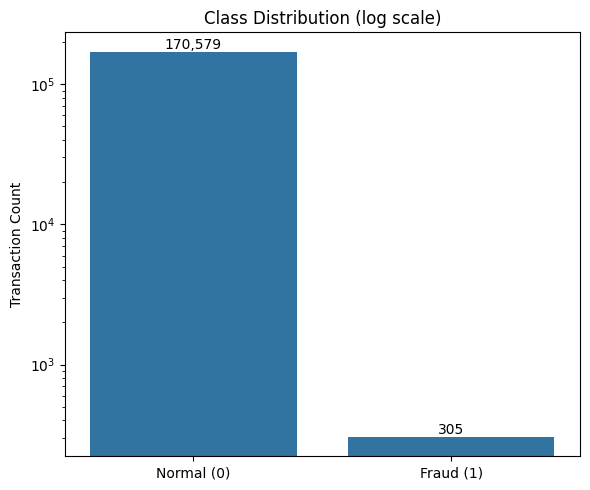

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.countplot(data= df, x = 'Class', ax = ax)
ax.set_yscale('log')
ax.set_xticklabels(['Normal (0)', 'Fraud (1)'])
ax.set_title('Class Distribution (log scale)')
ax.set_xlabel('')
ax.set_ylabel('Transaction Count')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}')

plt.tight_layout()
plt.show()

**Insight**
- The dataset is highly imbalanced, with fraudulent transactions according for approximately 0.18% of all transactions. This significant class imbalance makes accuracy an unreliable standalone evaluation metric, as a model that predicts every transaction as legitimate(Normal) could achieve a high accuracy while failing to detect fraudulent transactions. Therefore, we should prioritize metrics such as precision, Recall, F1-score and PR-AUC to better evaluate fraud detection performance.

- we will likely need to address this using techniques like `Oversampling`, `Undersampling` or `SMOTE`

<a id='3'></a>
## 3. Time & Amount Analysis

In [11]:
print('Time and Amount Analysis: ')
print(df[['Time', 'Amount']].describe())

Time and Amount Analysis: 
                Time         Amount
count  170884.000000  170884.000000
mean    94966.107886      88.511723
std     47464.723773     256.737144
min         0.000000       0.000000
25%     54348.000000       5.637500
50%     84923.500000      22.020000
75%    139404.000000      77.650000
max    172792.000000   25691.160000


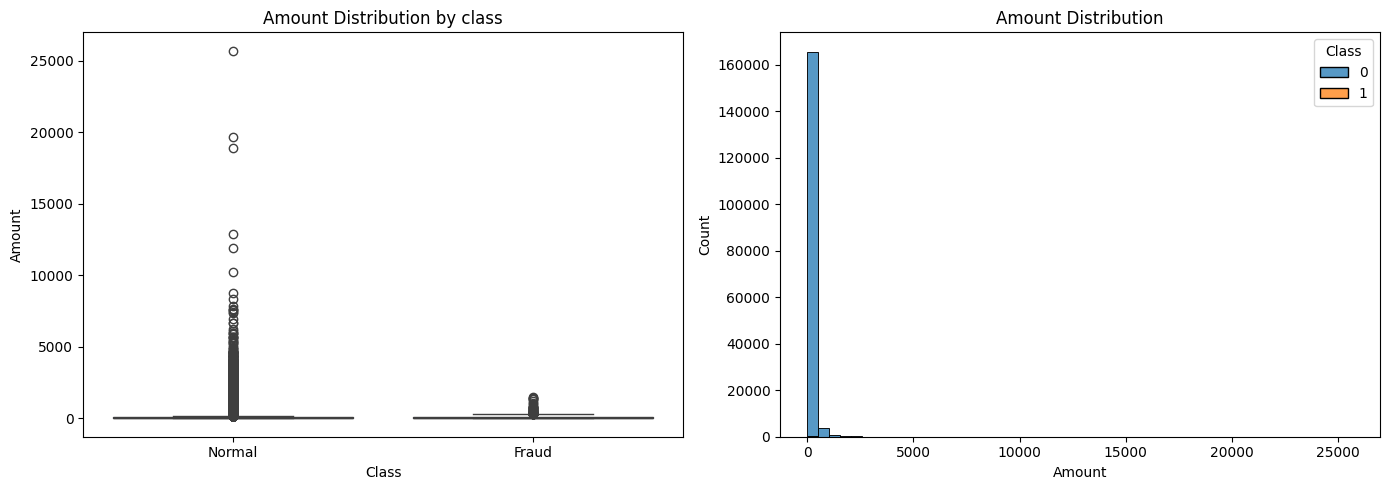

In [14]:
# Visualize amount distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data= df, x = 'Class', y= 'Amount', ax= axes[0])
axes[0].set_title('Amount Distribution by class')
axes[0].set_xticklabels(['Normal', 'Fraud'])

sns.histplot(
    data= df,
    x = 'Amount',
    hue = 'Class',
    multiple= 'stack',
    bins= 50,
    ax=axes[1]
)

axes[1].set_title('Amount Distribution')
plt.tight_layout()
plt.show()

**Note** 
- data distribution is positively skewed (or right-skewed) and there are an outliers

- We will apply log transformation and see the results

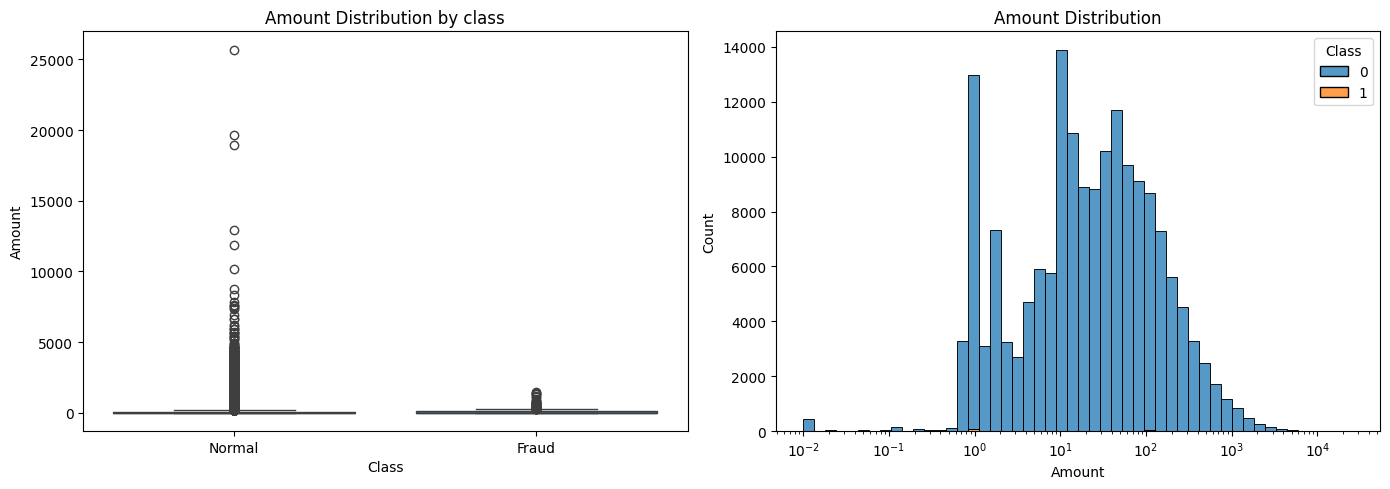

In [15]:
# Visualize amount distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data= df, x = 'Class', y= 'Amount', ax= axes[0])
axes[0].set_title('Amount Distribution by class')
axes[0].set_xticklabels(['Normal', 'Fraud'])

sns.histplot(
    data= df,
    x = 'Amount',
    hue = 'Class',
    multiple= 'stack',
    bins= 50,
    log_scale= True,
    ax=axes[1]
)

axes[1].set_title('Amount Distribution')
plt.tight_layout()
plt.show()

- After apply `log` , data distribution becomes normal. 

In [17]:
# Time Analysis
# Time is elapsed seconds; Class: 1 = fraud, 0 = normal
df["hour"] = ((df["Time"] % 86400) // 3600).astype(int)

time_summary = df.groupby("hour").agg(
    transactions=("Class", "size"),
    fraud_transactions=("Class", "sum"),
    fraud_rate=("Class", "mean")
)

print(time_summary)

      transactions  fraud_transactions  fraud_rate
hour                                              
0             4559                   5    0.001097
1             2484                   8    0.003221
2             2004                  35    0.017465
3             2029                  10    0.004929
4             1324                  15    0.011329
5             1848                   7    0.003788
6             2479                   4    0.001614
7             4345                  16    0.003682
8             6168                   5    0.000811
9             9502                   9    0.000947
10            9953                   2    0.000201
11           10004                  31    0.003099
12            9399                  11    0.001170
13            9240                   9    0.000974
14            9937                  12    0.001208
15            9876                  18    0.001823
16            9940                  15    0.001509
17            9796             

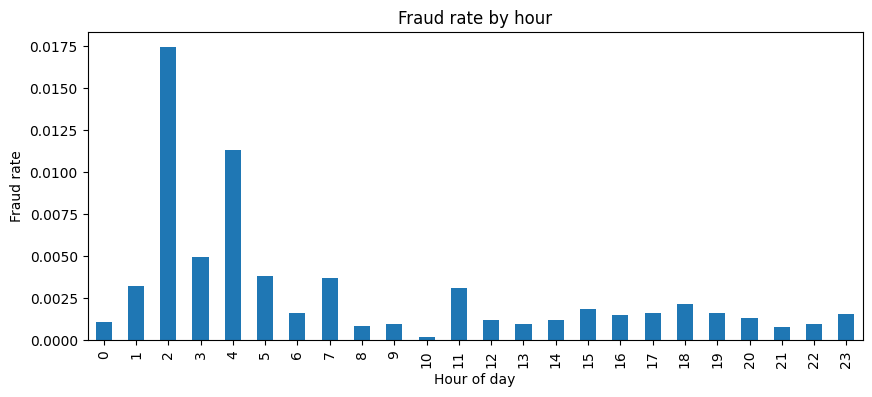

In [18]:
time_summary["fraud_rate"].plot(kind="bar", figsize=(10, 4))
plt.xlabel("Hour of day")
plt.ylabel("Fraud rate")
plt.title("Fraud rate by hour")
plt.show()

- The fraud rate is highest at `hour 2` (about 1.75%) and `hour 4` (about 1.1%) while remain hours remain below 0.5%.

In [30]:
# Analize anonymous features
print("Anonymous Features Statistics:")

v_coulmns = [col for col in df.columns if col.startswith('V')]

# Calculate skewness and kurtosis
skewness = df[v_coulmns].skew()
kurtosis = df[v_coulmns].kurtosis()

print(f'Top 5 most skewed features: ')
print(skewness.sort_values(ascending=False).head())
print('-'*20)
print(f'Top 5 most kurtosis features: ')
print(kurtosis.sort_values(ascending=False).head())



Anonymous Features Statistics:
Top 5 most skewed features: 
V28    5.064013
V7     4.421435
V21    3.463795
V6     2.234061
V10    1.003994
dtype: float64
--------------------
Top 5 most kurtosis features: 
V7     583.739435
V28    467.278081
V23    358.054886
V20    343.421652
V5     305.283308
dtype: float64


- Skewness and kurtosis values give you an idea about the distribution of these anonymized features. High skewness indicates a long tail, and high kurtosis suggests heavy tails with more extreme values. These features might benefit from transformations to make their distributions more normal.

<a id='4'></a>
## 4. Correlation Analysis

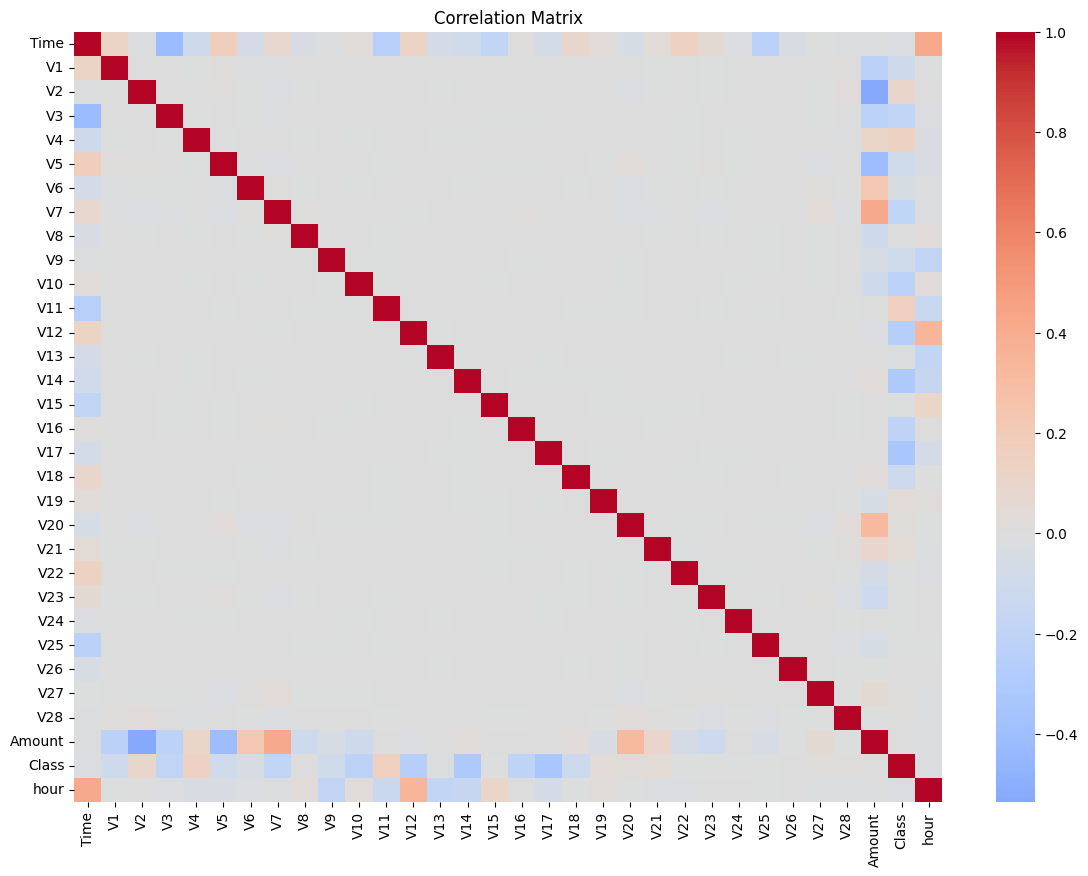

In [37]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Matrix')
plt.show()

**Observations**
- The PCA components (V1-V28) nearly uncorrelated with each other.

- Correlation with `Class` is weak overall with the strongest negatives associations for `V17` - `V14` - `V12` - `V10` and positive ones for `V11` - `V4`- `V2`.

- The strongest correlations in the matrix involve `Amount` with (`V2`- `V7`, `V5` - `V20`) and `Time` with (`V3` - `V11` - `V25`)

- Linear correlation with the target is weak so, Correlation heatmap alone is not enough to judge feature importance.

<a id='5'></a>
## 5. Statistical Feature Significance

Since `Class` is a binary variable (0 = normal, 1 = fraudulent) and most V features do not follow a normal distribution, non-parametric statistical tests are used to compare the feature distributions between normal and fraudulent transactions.

Specifically, the `Mann-Whitney U test` and `Kolmogorov-Smirnov (KS) test` are applied to each feature to determine whether its distribution differs significantly between the two classes.

In [39]:
results = []

for col in df.columns:
    if col in ('Class', 'Time', 'hour'):
        continue

    normal_vals = df.loc[df['Class'] == 0, col]
    fraud_vals = df.loc[df['Class'] == 1, col]

    u_stat, u_p = mannwhitneyu(normal_vals, fraud_vals, alternative=
                               'two-sided')
    ks_stat, ks_p = ks_2samp(normal_vals, fraud_vals)

    results.append({
        'Feature': col,
        'mannwhitney_p' : u_p,
        'ks_stat': ks_stat,
        'ks_p' : ks_p
    })


significance_df = pd.DataFrame(results).sort_values('mannwhitney_p').reset_index(drop=True)
top_features = significance_df['Feature'].head(10).tolist()

significance_df.head(10)

,Feature,mannwhitney_p,ks_stat,ks_p
0,V14,1.117429e-157,0.829016,4.872553e-232
1,V12,1.501722e-153,0.779156,1.199277e-195
2,V4,7.209137e-153,0.774337,1.686773e-192
3,V11,1.270366e-138,0.754130,7.228768e-180
4,V10,4.525965e-135,0.790148,4.812929e-203
5,V3,3.724298e-131,0.686167,6.633129e-143
6,V2,8.863961e-100,0.632463,2.182769e-118
7,V7,2.009580e-93,0.644416,1.531774e-123
8,V16,5.817812e-93,0.686136,6.865872e-143
9,V9,1.740039e-87,0.559299,4.118652e-90


#### I will take `V14` as an example to see how its distribution different if normal and fraud transaction

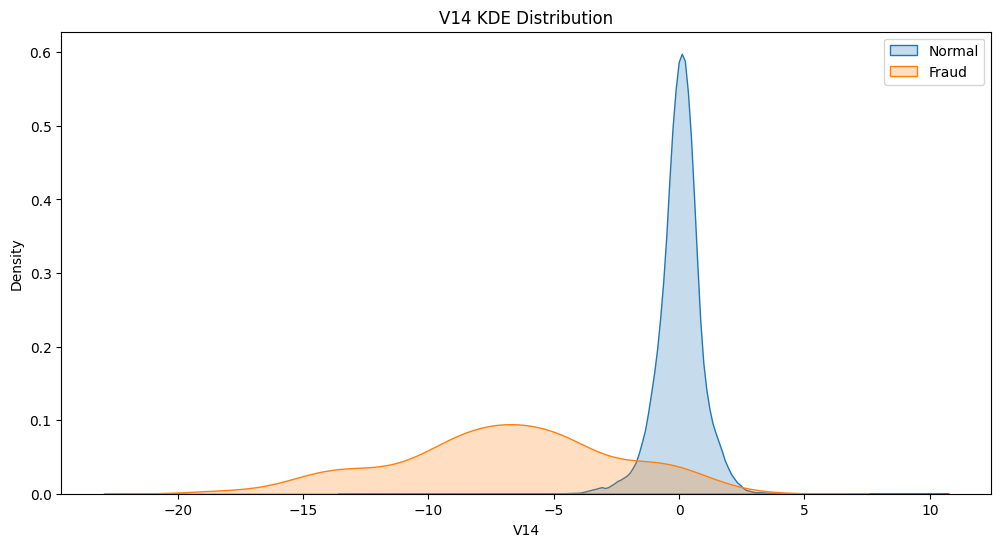

In [40]:
plt.figure(figsize=(12, 6))

# Normal Transaction
sns.kdeplot(
    data= df[df['Class'] == 0],
    x = 'V14',
    label = 'Normal',
    fill= True
)

# Fraud Transaction
sns.kdeplot(
    data= df[df['Class'] == 1],
    x = 'V14',
    label = 'Fraud',
    fill= True
)

plt.title('V14 KDE Distribution')
plt.xlabel('V14')
plt.ylabel('Density')
plt.legend()
plt.show()

**Insight:** V14 alone cannot perfectly distinguish normal from fraudulent transactions because their value distributions overlap. Although it provides a strong signal, reliable fraud detection requires combining it with other features.

<a id='6'></a>
## 6. Outlier Analysis (IQR method)

In [41]:
def iqr_outlier_pct(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr , q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).mean() * 100

outlier_summary = pd.Series(
    {col: iqr_outlier_pct(df[col]) for col in df.columns if col not in ('Class', 'Time', 'hour')}
).sort_values(ascending= False)

outlier_summary.head(10)

V27       13.610988
Amount    11.063646
V28       10.565647
V20        9.762178
V8         8.600571
V6         8.051661
V23        6.545961
V12        5.417710
V21        5.176026
V14        4.930245
dtype: float64

**Observation:** for examples The `Amount` feature contains a relatively high proportion of potential outliers, with approximately **11% of its values falling outside the IQR-based boundaries**.

- The goal of this analysis to show unusual distribution

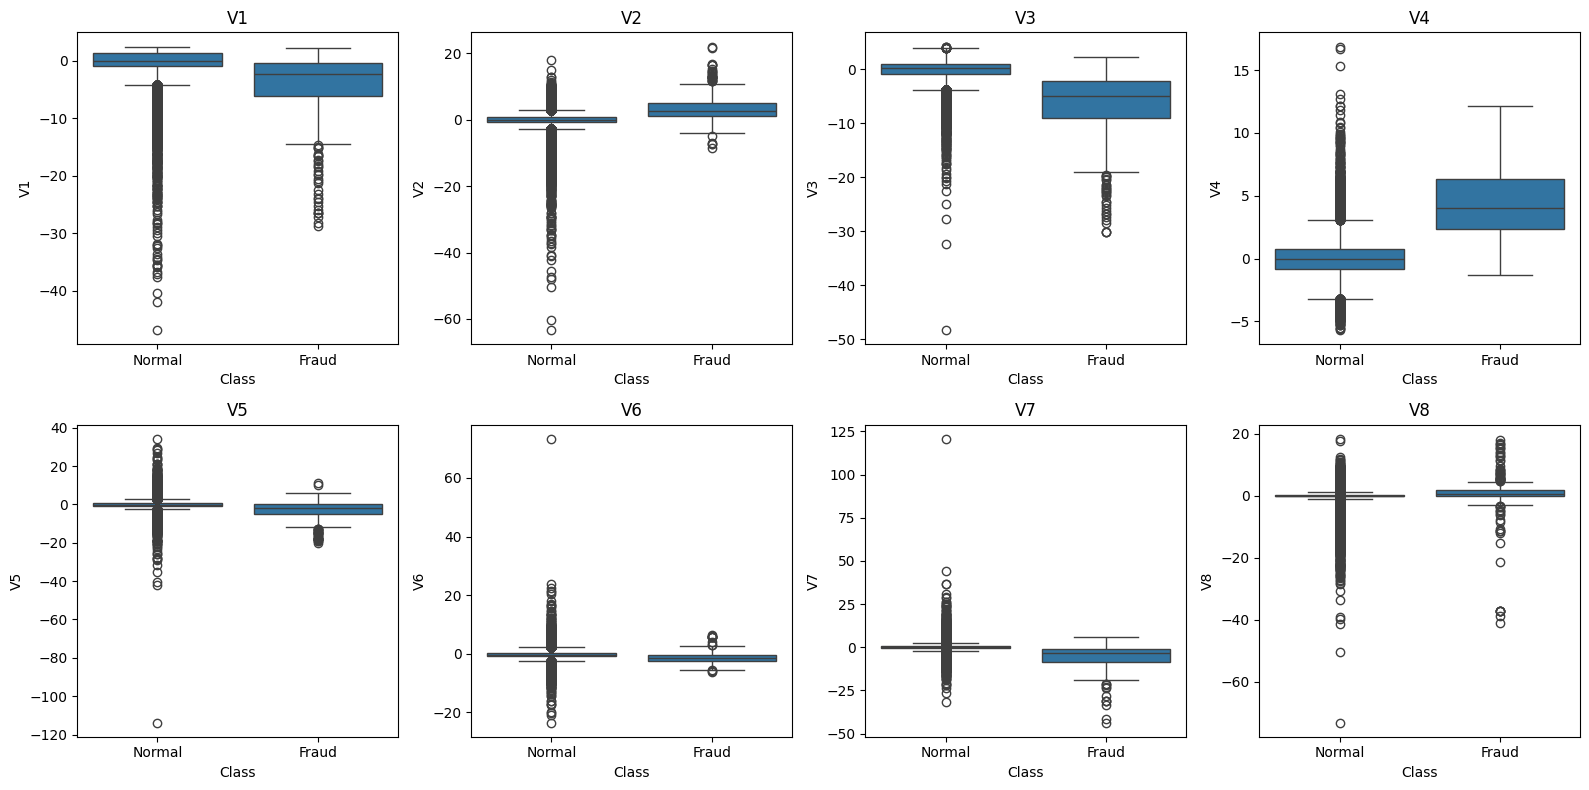

In [42]:
v_features = [f'V{i}' for i in range(1, 9)]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, feature in zip(axes.flat, v_features):
    sns.boxplot(data= df, x = 'Class', y=feature, ax=ax)
    ax.set_xticklabels(['Normal', 'Fraud'])
    ax.set_title(feature)


plt.tight_layout()
plt.show()

**Insight** Several `V` features carry a high percentage of statistical outliers by the IQR rule — this is expected and largely benign for PCA components (extreme values often *are* the fraud signal, not noise). This means aggressive outlier removal is **not** recommended here, since it risks discarding the very transactions the model needs to learn from. Robust or tree-based models that aren't sensitive to extreme values are a better fit than outlier-sensitive approaches.

<a id='7'></a>
## 7. Distribution Comparison for Top Features

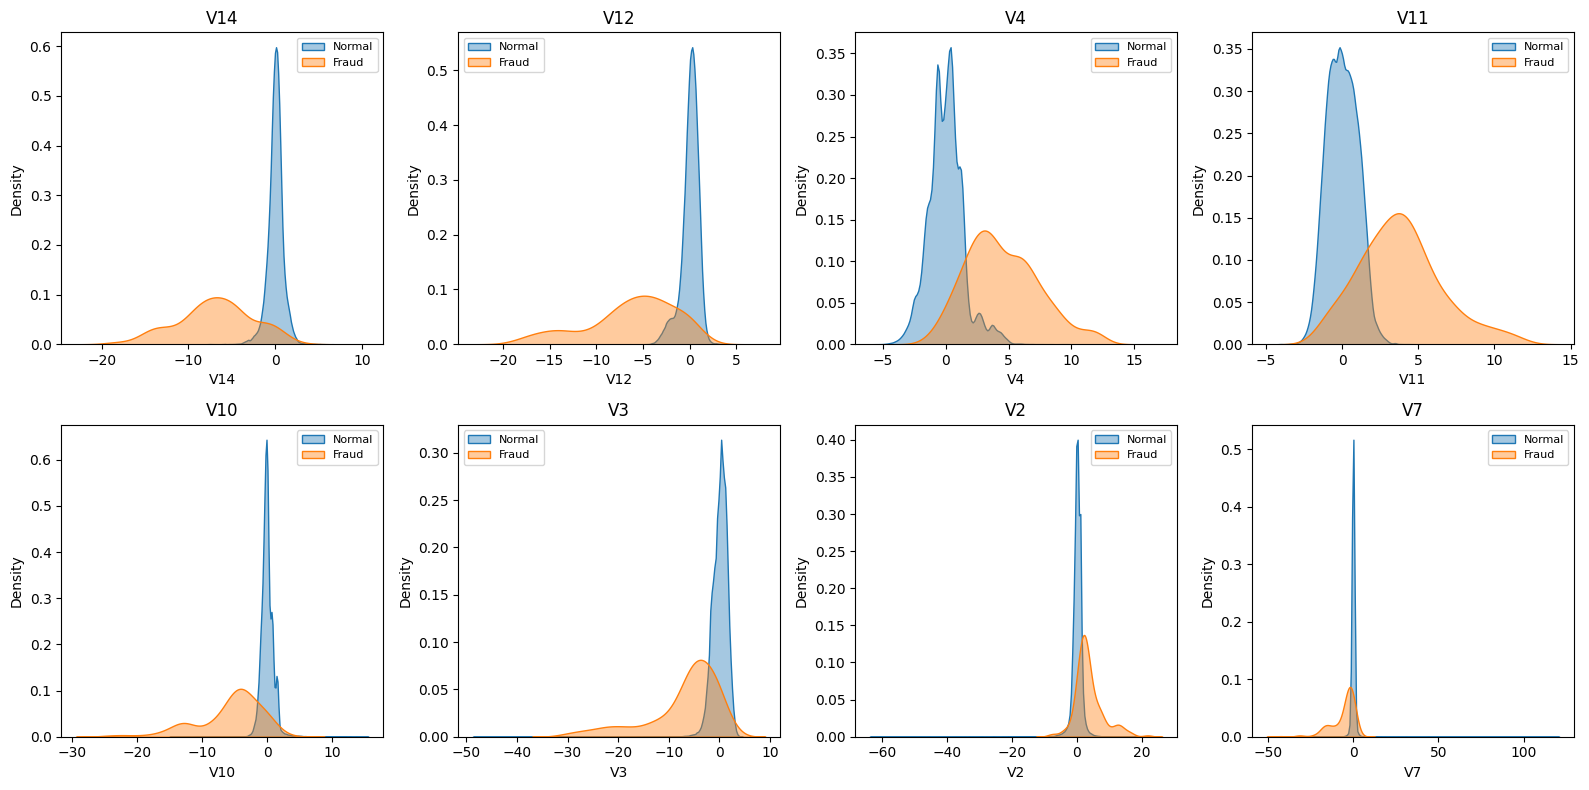

In [43]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, feature in zip(axes.flat, top_features[:8]):
    sns.kdeplot(data= df.loc[df['Class'] == 0, feature], label = 'Normal', fill=True,alpha=0.4, ax=ax)
    sns.kdeplot(data= df.loc[df['Class'] == 1, feature], label = 'Fraud', fill=True,alpha=0.4, ax=ax)

    ax.set_title(feature)
    ax.legend(fontsize = 8)

plt.tight_layout()
plt.show()

**Insight**
- Some features provide a strong individual signal for distinguishig fraud from normal transactions.
- Features with significant overlap between the two distributions have weaker individual signals.
- However, these features may still provide useful information when combined with other features.

<a id='8'></a>
## 8. Key Findings in EDA

- Dataset is highly imbalanced fraudulent transactions represent approximately **0.18%** of transactions. So the accuracy metric will be misleading.

- We need to apply on of the sampling techniques like `SMOTE`

- Most of the features contains outliers.

- The V1–V28 features are not strongly correlated, so none need to be removed for redundancy. The top features from Section 5 are good starting points for checking which features matter most in the model.


 